In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
# 08 — FINAL ANALYSIS & EVALUATION

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

PROJECT_DIR = "/content/drive/MyDrive/Multimedia_Authentication"

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CM_DIR = os.path.join(RESULTS_DIR, "confusion_matrices")
FEATURE_DIR = os.path.join(PROJECT_DIR, "features")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CM_DIR, exist_ok=True)

print("Final analysis workspace ready.")
print("Project:", PROJECT_DIR)
print("Results:", RESULTS_DIR)
print("Models :", MODEL_DIR)
print("Features:", FEATURE_DIR)

Final analysis workspace ready.
Project: /content/drive/MyDrive/Multimedia_Authentication
Results: /content/drive/MyDrive/Multimedia_Authentication/results
Models : /content/drive/MyDrive/Multimedia_Authentication/models
Features: /content/drive/MyDrive/Multimedia_Authentication/features


In [21]:
import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

GATED_CHECKPOINT = os.path.join(
    MODEL_DIR,
    "gated_fusion_resnet18_auc_best.pth"
)

TRAIN_FEATURES = os.path.join(
    FEATURE_DIR,
    "gated_train_features.pt"
)

VAL_FEATURES = os.path.join(
    FEATURE_DIR,
    "gated_val_features.pt"
)

TEST_FEATURES = os.path.join(
    FEATURE_DIR,
    "gated_test_features.pt"
)

class FeatureGatedFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(1024, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        # Initialize final gate layer so alpha starts at 0.5
        nn.init.zeros_(self.gate[-2].weight)
        nn.init.zeros_(self.gate[-2].bias)

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 2)
        )

    def forward(self, spatial, frequency, return_gate=False):

        combined = torch.cat([spatial, frequency], dim=1)

        alpha = self.gate(combined)

        fused = (
            alpha * spatial
            + (1 - alpha) * frequency
        )

        logits = self.classifier(fused)

        if return_gate:
            return logits, alpha

        return logits



model = FeatureGatedFusion().to(DEVICE)

checkpoint = torch.load(
    GATED_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

print("\nAdaptive Gated Fusion model loaded successfully.")
print("Checkpoint:", GATED_CHECKPOINT)


train_data = torch.load(TRAIN_FEATURES, map_location="cpu", weights_only=False)
val_data   = torch.load(VAL_FEATURES, map_location="cpu", weights_only=False)
test_data  = torch.load(TEST_FEATURES, map_location="cpu", weights_only=False)

print("\nFeature files loaded.")

print("\nTrain object type:", type(train_data))
print("Validation object type:", type(val_data))
print("Test object type:", type(test_data))

Device: cpu

Adaptive Gated Fusion model loaded successfully.
Checkpoint: /content/drive/MyDrive/Multimedia_Authentication/models/gated_fusion_resnet18_auc_best.pth

Feature files loaded.

Train object type: <class 'dict'>
Validation object type: <class 'dict'>
Test object type: <class 'dict'>


In [22]:


for name, data in [
    ("TRAIN", train_data),
    ("VALIDATION", val_data),
    ("TEST", test_data)
]:
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Keys:", list(data.keys()))

    for key, value in data.items():

        if torch.is_tensor(value):
            print(
                f"{key:15} | Tensor | "
                f"shape={tuple(value.shape)} | "
                f"dtype={value.dtype}"
            )

        elif isinstance(value, np.ndarray):
            print(
                f"{key:15} | NumPy  | "
                f"shape={value.shape} | "
                f"dtype={value.dtype}"
            )

        elif isinstance(value, list):
            print(
                f"{key:15} | List   | "
                f"length={len(value)}"
            )

        else:
            print(
                f"{key:15} | {type(value)}"
            )


TRAIN
Keys: ['spatial', 'frequency', 'labels']
spatial         | Tensor | shape=(1770, 512) | dtype=torch.float32
frequency       | Tensor | shape=(1770, 512) | dtype=torch.float32
labels          | Tensor | shape=(1770,) | dtype=torch.int64

VALIDATION
Keys: ['spatial', 'frequency', 'labels']
spatial         | Tensor | shape=(392, 512) | dtype=torch.float32
frequency       | Tensor | shape=(392, 512) | dtype=torch.float32
labels          | Tensor | shape=(392,) | dtype=torch.int64

TEST
Keys: ['spatial', 'frequency', 'labels']
spatial         | Tensor | shape=(418, 512) | dtype=torch.float32
frequency       | Tensor | shape=(418, 512) | dtype=torch.float32
labels          | Tensor | shape=(418,) | dtype=torch.int64


In [23]:

def get_predictions(model, data, device):
    """
    Generate probabilities, predictions and gate values
    from saved spatial/frequency features.
    """

    spatial = data["spatial"].to(device)
    frequency = data["frequency"].to(device)
    labels = data["labels"].to(device)

    with torch.no_grad():
        logits, alpha = model(
            spatial,
            frequency,
            return_gate=True
        )

        probabilities = torch.softmax(logits, dim=1)[:, 1]
        predictions = (probabilities >= 0.5).long()

    return (
        labels.cpu().numpy(),
        probabilities.cpu().numpy(),
        predictions.cpu().numpy(),
        alpha.squeeze(1).cpu().numpy()
    )


train_true, train_probs, train_preds, train_gates = \
    get_predictions(model, train_data, DEVICE)

val_true, val_probs, val_preds, val_gates = \
    get_predictions(model, val_data, DEVICE)

test_true, test_probs, test_preds, test_gates = \
    get_predictions(model, test_data, DEVICE)


print("Prediction generation complete.\n")

print("TRAIN")
print("Samples:", len(train_true))
print("Probability range:",
      round(train_probs.min(), 4),
      "to",
      round(train_probs.max(), 4))

print("\nVALIDATION")
print("Samples:", len(val_true))
print("Probability range:",
      round(val_probs.min(), 4),
      "to",
      round(val_probs.max(), 4))

print("\nTEST")
print("Samples:", len(test_true))
print("Probability range:",
      round(test_probs.min(), 4),
      "to",
      round(test_probs.max(), 4))

print("\nTest confusion matrix:")
print(confusion_matrix(test_true, test_preds))

Prediction generation complete.

TRAIN
Samples: 1770
Probability range: 0.0 to 1.0

VALIDATION
Samples: 392
Probability range: 0.0 to 1.0

TEST
Samples: 418
Probability range: 0.0 to 1.0

Test confusion matrix:
[[ 32  32]
 [ 28 326]]


Adaptive Gated Fusion — ROC Analysis
ROC-AUC: 0.8038 (80.38%)


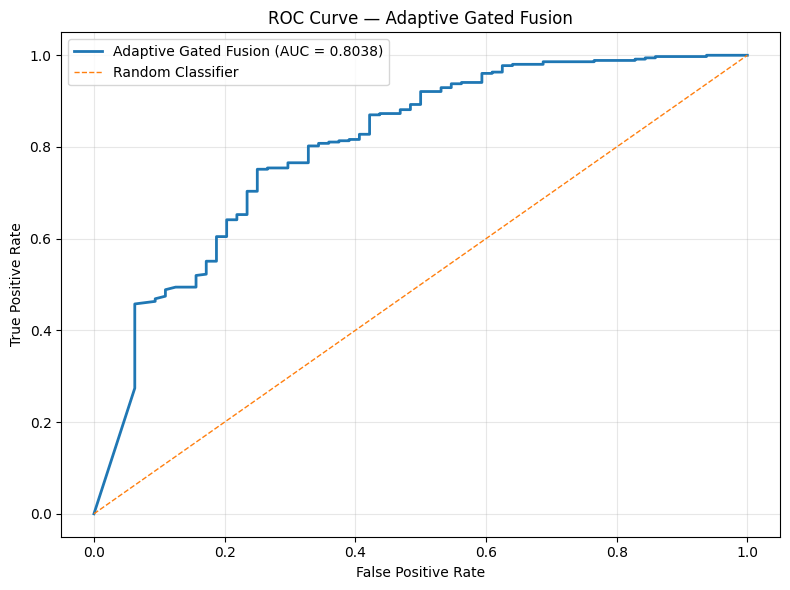


ROC curve saved to:
/content/drive/MyDrive/Multimedia_Authentication/results/adaptive_gated_roc_curve.png


In [24]:
fpr, tpr, thresholds = roc_curve(
    test_true,
    test_probs
)

test_auc = auc(fpr, tpr)

print("Adaptive Gated Fusion — ROC Analysis")
print("=" * 50)
print(f"ROC-AUC: {test_auc:.4f} ({test_auc * 100:.2f}%)")


plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Adaptive Gated Fusion (AUC = {test_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Adaptive Gated Fusion")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

roc_path = os.path.join(
    RESULTS_DIR,
    "adaptive_gated_roc_curve.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nROC curve saved to:")
print(roc_path)

Validation Threshold Analysis


,Threshold,Accuracy,Precision,Recall,F1,False Positive Rate,False Negative Rate,TN,FP,FN,TP
0,0.10,0.8622,0.8947,0.9444,0.9189,0.5294,0.0556,32,36,18,306
1,0.15,0.8673,0.9000,0.9444,0.9217,0.5000,0.0556,34,34,18,306
2,0.20,0.8648,0.8997,0.9414,0.9201,0.5000,0.0586,34,34,19,305
3,0.25,0.8622,0.8994,0.9383,0.9184,0.5000,0.0617,34,34,20,304
4,0.30,0.8648,0.9021,0.9383,0.9198,0.4853,0.0617,35,33,20,304
5,0.35,0.8571,0.9012,0.9290,0.9149,0.4853,0.0710,35,33,23,301
6,0.40,0.8444,0.8997,0.9136,0.9066,0.4853,0.0864,35,33,28,296
7,0.45,0.8418,0.8994,0.9105,0.9049,0.4853,0.0895,35,33,29,295
8,0.50,0.8418,0.9018,0.9074,0.9046,0.4706,0.0926,36,32,30,294
9,0.55,0.8367,0.9012,0.9012,0.9012,0.4706,0.0988,36,32,32,292



Best Validation-F1 Threshold
Threshold : 0.15
F1        : 0.9217
Precision : 0.9000
Recall    : 0.9444


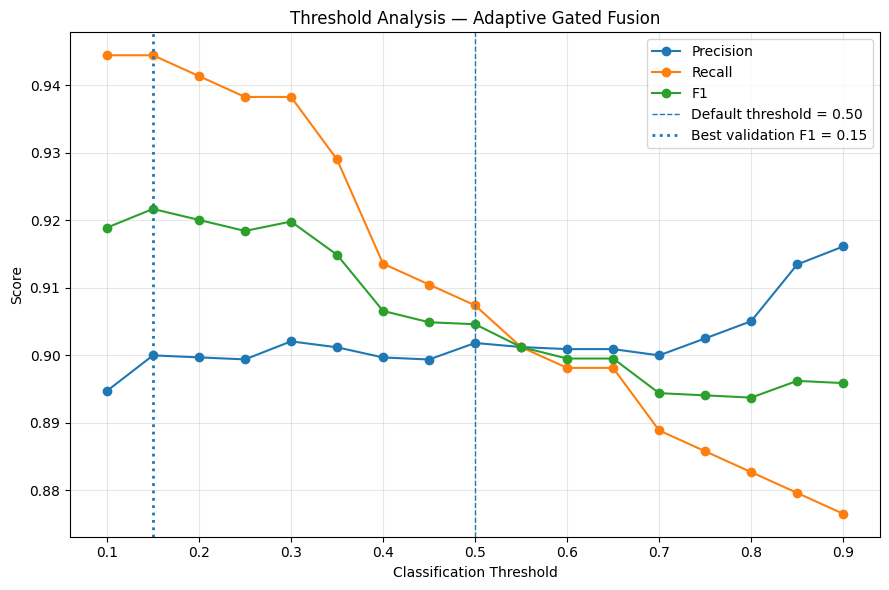


Threshold analysis saved to:
/content/drive/MyDrive/Multimedia_Authentication/results/adaptive_threshold_analysis.png


In [25]:
# THRESHOLD ANALYSIS

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)


threshold_values = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in threshold_values:

    preds = (val_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_true,
        preds,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(val_true, preds),
        "Precision": precision_score(
            val_true, preds, zero_division=0
        ),
        "Recall": recall_score(
            val_true, preds, zero_division=0
        ),
        "F1": f1_score(
            val_true, preds, zero_division=0
        ),
        "False Positive Rate": fp / (fp + tn)
            if (fp + tn) > 0 else 0,
        "False Negative Rate": fn / (fn + tp)
            if (fn + tp) > 0 else 0,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(threshold_results)

print("Validation Threshold Analysis")
print("=" * 80)

display(
    threshold_df.round(4)
)

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_f1_threshold = best_f1_row["Threshold"]

print("\n" + "=" * 80)
print("Best Validation-F1 Threshold")
print("=" * 80)

print(
    f"Threshold : {best_f1_threshold:.2f}"
)

print(
    f"F1        : {best_f1_row['F1']:.4f}"
)

print(
    f"Precision : {best_f1_row['Precision']:.4f}"
)

print(
    f"Recall    : {best_f1_row['Recall']:.4f}"
)


# ------------------------------------------------------------
# Plot threshold behaviour
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="Default threshold = 0.50"
)

plt.axvline(
    best_f1_threshold,
    linestyle=":",
    linewidth=2,
    label=f"Best validation F1 = {best_f1_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Analysis — Adaptive Gated Fusion")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

threshold_plot_path = os.path.join(
    RESULTS_DIR,
    "adaptive_threshold_analysis.png"
)

plt.savefig(
    threshold_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nThreshold analysis saved to:")
print(threshold_plot_path)

In [26]:
# FINAL TEST THRESHOLD COMPARISON

def evaluate_threshold(y_true, probabilities, threshold):

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "False Positive Rate": fp / (fp + tn),
        "False Negative Rate": fn / (fn + tp),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


default_result = evaluate_threshold(
    test_true,
    test_probs,
    0.50
)

selected_result = evaluate_threshold(
    test_true,
    test_probs,
    best_f1_threshold
)


comparison_df = pd.DataFrame([
    default_result,
    selected_result
])

print("FINAL TEST THRESHOLD COMPARISON")
print("=" * 90)

display(
    comparison_df.round(4)
)



threshold_test_path = os.path.join(
    RESULTS_DIR,
    "adaptive_test_threshold_comparison.csv"
)

comparison_df.to_csv(
    threshold_test_path,
    index=False
)

print("\nSaved to:")
print(threshold_test_path)


selected_preds = (
    test_probs >= best_f1_threshold
).astype(int)

selected_cm = confusion_matrix(
    test_true,
    selected_preds,
    labels=[0, 1]
)

print("\nConfusion Matrix at Selected Threshold")
print(f"Threshold = {best_f1_threshold:.2f}")
print("----------------------------------------")
print(selected_cm)

FINAL TEST THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1,False Positive Rate,False Negative Rate,TN,FP,FN,TP
0,0.50,0.8565,0.9106,0.9209,0.9157,0.5000,0.0791,32,32,28,326
1,0.15,0.8636,0.9024,0.9407,0.9212,0.5625,0.0593,28,36,21,333



Saved to:
/content/drive/MyDrive/Multimedia_Authentication/results/adaptive_test_threshold_comparison.csv

Confusion Matrix at Selected Threshold
Threshold = 0.15
----------------------------------------
[[ 28  36]
 [ 21 333]]


In [27]:


final_comparison = pd.DataFrame([
    {
        "Operating Point": "Default (0.50)",
        "Accuracy": 0.8565,
        "Precision": 0.9106,
        "Recall": 0.9209,
        "F1": 0.9157,
        "False Positives": 32,
        "False Negatives": 28
    },
    {
        "Operating Point": f"Selected ({best_f1_threshold:.2f})",
        "Accuracy": selected_result["Accuracy"],
        "Precision": selected_result["Precision"],
        "Recall": selected_result["Recall"],
        "F1": selected_result["F1"],
        "False Positives": selected_result["FP"],
        "False Negatives": selected_result["FN"]
    }
])

display(final_comparison.round(4))

final_comparison_path = os.path.join(
    RESULTS_DIR,
    "adaptive_final_operating_point_comparison.csv"
)

final_comparison.to_csv(
    final_comparison_path,
    index=False
)

print("Saved:", final_comparison_path)

,Operating Point,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,Default (0.50),0.8565,0.9106,0.9209,0.9157,32,28
1,Selected (0.15),0.8636,0.9024,0.9407,0.9212,36,21


Saved: /content/drive/MyDrive/Multimedia_Authentication/results/adaptive_final_operating_point_comparison.csv


Adaptive Gated Fusion — Test Confusion Matrix
Threshold = 0.50
----------------------------------------
[[ 32  32]
 [ 28 326]]


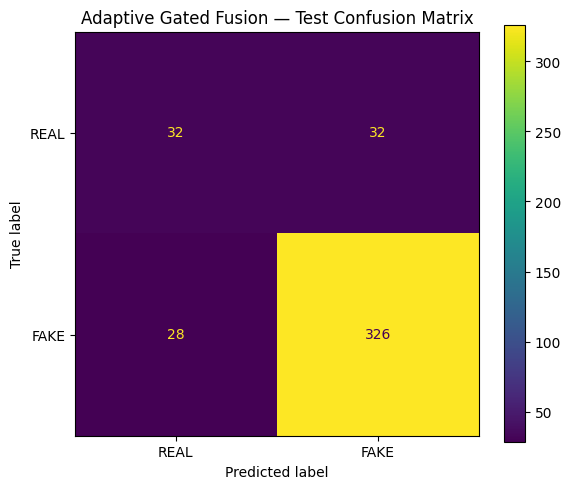


Saved: /content/drive/MyDrive/Multimedia_Authentication/results/confusion_matrices/adaptive_gated_final_confusion_matrix.png


In [28]:
# FINAL CONFUSION MATRIX


from sklearn.metrics import ConfusionMatrixDisplay

final_cm = confusion_matrix(
    test_true,
    test_preds,
    labels=[0, 1]
)

print("Adaptive Gated Fusion — Test Confusion Matrix")
print("Threshold = 0.50")
print("----------------------------------------")
print(final_cm)

plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["REAL", "FAKE"]
)

disp.plot(
    values_format="d",
    ax=plt.gca()
)

plt.title("Adaptive Gated Fusion — Test Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(
    CM_DIR,
    "adaptive_gated_final_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", cm_path)

In [29]:
error_df = pd.DataFrame({
    "True Label": test_true,
    "Predicted Label": test_preds,
    "FAKE Probability": test_probs,
    "Gate Alpha": test_gates
})

false_positives = error_df[
    (error_df["True Label"] == 0) &
    (error_df["Predicted Label"] == 1)
].copy()

false_negatives = error_df[
    (error_df["True Label"] == 1) &
    (error_df["Predicted Label"] == 0)
].copy()

print("ERROR ANALYSIS")
print("=" * 60)

print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))
print("Total Errors   :", len(false_positives) + len(false_negatives))


false_positives["Confidence"] = (
    false_positives["FAKE Probability"]
)

false_negatives["Confidence"] = (
    1 - false_negatives["FAKE Probability"]
)

print("\nMost confident False Positives:")
display(
    false_positives
    .sort_values("Confidence", ascending=False)
    .head(5)
    .round(4)
)

print("\nMost confident False Negatives:")
display(
    false_negatives
    .sort_values("Confidence", ascending=False)
    .head(5)
    .round(4)
)


fp_path = os.path.join(
    RESULTS_DIR,
    "adaptive_false_positives.csv"
)

fn_path = os.path.join(
    RESULTS_DIR,
    "adaptive_false_negatives.csv"
)

false_positives.to_csv(fp_path, index=False)
false_negatives.to_csv(fn_path, index=False)

print("\nSaved:")
print(fp_path)
print(fn_path)

ERROR ANALYSIS
False Positives: 32
False Negatives: 28
Total Errors   : 60

Most confident False Positives:


,True Label,Predicted Label,FAKE Probability,Gate Alpha,Confidence
117,0,1,1.0,1.0,1.0
96,0,1,1.0,1.0,1.0
415,0,1,1.0,1.0,1.0
323,0,1,1.0,1.0,1.0
389,0,1,1.0,1.0,1.0



Most confident False Negatives:


,True Label,Predicted Label,FAKE Probability,Gate Alpha,Confidence
261,1,0,0.0000,1.0000,1.0000
6,1,0,0.0003,0.9999,0.9997
10,1,0,0.0007,0.9999,0.9993
121,1,0,0.0012,1.0000,0.9988
279,1,0,0.0023,0.9999,0.9977



Saved:
/content/drive/MyDrive/Multimedia_Authentication/results/adaptive_false_positives.csv
/content/drive/MyDrive/Multimedia_Authentication/results/adaptive_false_negatives.csv


ADAPTIVE GATE ANALYSIS
Mean alpha       : 0.9999
Std alpha        : 0.0002
Minimum alpha    : 0.9979
Maximum alpha    : 1.0000

REAL mean alpha  : 0.9999
FAKE mean alpha  : 0.9999


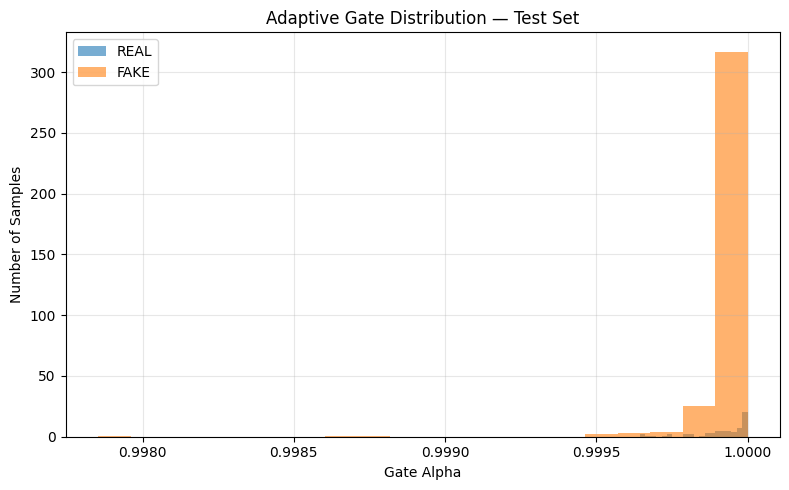


Saved: /content/drive/MyDrive/Multimedia_Authentication/results/adaptive_gate_distribution.png


In [30]:
print("ADAPTIVE GATE ANALYSIS")
print("=" * 60)

print(f"Mean alpha       : {test_gates.mean():.4f}")
print(f"Std alpha        : {test_gates.std():.4f}")
print(f"Minimum alpha    : {test_gates.min():.4f}")
print(f"Maximum alpha    : {test_gates.max():.4f}")

real_gates = test_gates[test_true == 0]
fake_gates = test_gates[test_true == 1]

print(f"\nREAL mean alpha  : {real_gates.mean():.4f}")
print(f"FAKE mean alpha  : {fake_gates.mean():.4f}")


# ------------------------------------------------------------
# Plot gate distribution
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    real_gates,
    bins=20,
    alpha=0.6,
    label="REAL"
)

plt.hist(
    fake_gates,
    bins=20,
    alpha=0.6,
    label="FAKE"
)

plt.xlabel("Gate Alpha")
plt.ylabel("Number of Samples")
plt.title("Adaptive Gate Distribution — Test Set")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

gate_path = os.path.join(
    RESULTS_DIR,
    "adaptive_gate_distribution.png"
)

plt.savefig(
    gate_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", gate_path)

In [31]:
# FINAL MODEL COMPARISON

model_comparison = pd.DataFrame([
    {
        "Model": "Spatial ResNet18",
        "Accuracy": 0.8517,
        "Precision": 0.9101,
        "Recall": 0.9153,
        "F1": 0.9127,
        "ROC-AUC": 0.8050
    },
    {
        "Model": "Frequency DWT + ResNet18",
        "Accuracy": 0.8469,
        "Precision": 0.8469,
        "Recall": 1.0000,
        "F1": 0.9171,
        "ROC-AUC": 0.5784
    },
    {
        "Model": "Fixed Fusion",
        "Accuracy": 0.8541,
        "Precision": 0.8865,
        "Recall": 0.9492,
        "F1": 0.9168,
        "ROC-AUC": 0.7821
    },
    {
        "Model": "Adaptive Gated Fusion",
        "Accuracy": 0.8565,
        "Precision": 0.9106,
        "Recall": 0.9209,
        "F1": 0.9157,
        "ROC-AUC": 0.8038
    }
])

print("FINAL MODEL COMPARISON")
print("=" * 100)

display(
    model_comparison.round(4)
)


comparison_path = os.path.join(
    RESULTS_DIR,
    "final_model_comparison.csv"
)

model_comparison.to_csv(
    comparison_path,
    index=False
)

print("\nSaved:", comparison_path)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Spatial ResNet18,0.8517,0.9101,0.9153,0.9127,0.8050
1,Frequency DWT + ResNet18,0.8469,0.8469,1.0000,0.9171,0.5784
2,Fixed Fusion,0.8541,0.8865,0.9492,0.9168,0.7821
3,Adaptive Gated Fusion,0.8565,0.9106,0.9209,0.9157,0.8038



Saved: /content/drive/MyDrive/Multimedia_Authentication/results/final_model_comparison.csv


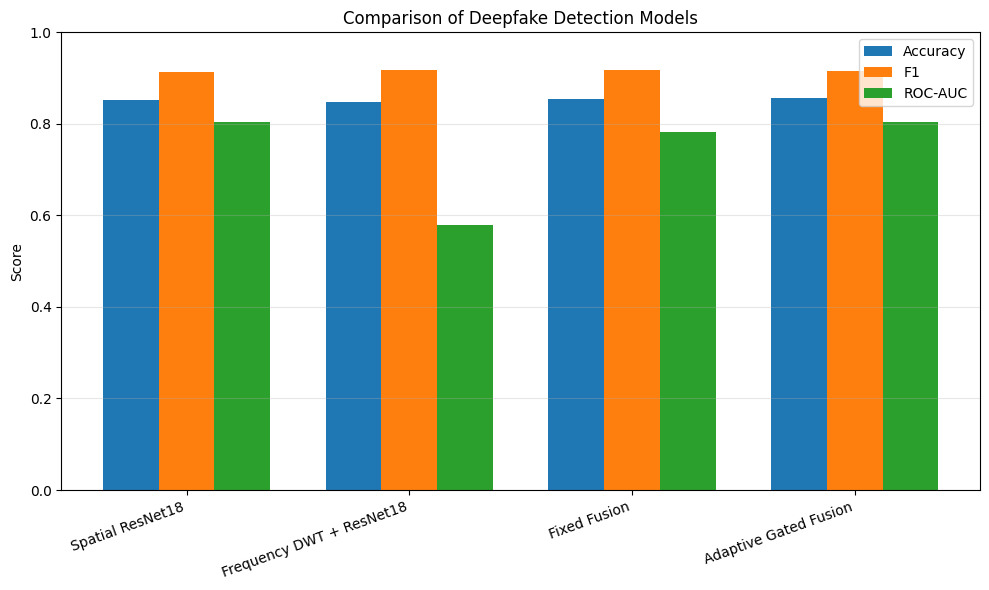

Saved: /content/drive/MyDrive/Multimedia_Authentication/results/final_model_comparison.png


In [32]:
# MODEL PERFORMANCE COMPARISON

plt.figure(figsize=(10, 6))

x = np.arange(len(model_comparison))
width = 0.25

plt.bar(
    x - width,
    model_comparison["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x,
    model_comparison["F1"],
    width,
    label="F1"
)

plt.bar(
    x + width,
    model_comparison["ROC-AUC"],
    width,
    label="ROC-AUC"
)

plt.xticks(
    x,
    model_comparison["Model"],
    rotation=20,
    ha="right"
)

plt.ylabel("Score")
plt.title("Comparison of Deepfake Detection Models")
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

comparison_plot_path = os.path.join(
    RESULTS_DIR,
    "final_model_comparison.png"
)

plt.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", comparison_plot_path)

In [33]:
final_conclusions = """
FINAL PROJECT CONCLUSIONS
==========================

1. A spatial ResNet18 branch was trained to learn visual artifacts
   from facial frames.

2. A frequency-domain branch using DWT + ResNet18 was evaluated
   to capture high-frequency manipulation artifacts.

3. Fixed spatial-frequency fusion combined both representations
   using feature concatenation.

4. Adaptive Gated Fusion was introduced to learn the contribution
   of the spatial and frequency representations.

5. On the test set, Adaptive Gated Fusion achieved:

   Accuracy  : 85.65%
   Precision : 91.06%
   Recall    : 92.09%
   F1 Score  : 91.57%
   ROC-AUC   : 80.38%

6. The adaptive gate strongly favored the spatial representation
   on the evaluated dataset, with mean alpha approximately 0.9999.

7. Threshold analysis showed that selecting a threshold of 0.15
   using validation data increased the test-set recall and F1
   compared with the default threshold of 0.50.

   Accuracy : 85.65% -> 86.36%
   Recall   : 92.09% -> 94.07%
   F1       : 91.57% -> 92.12%

   This came with an increase in false positives from 32 to 36
   and a reduction in false negatives from 28 to 21.

8. The model comparison demonstrates that different feature
   representations and fusion strategies produce different
   precision-recall and ranking behaviours.

9. The results also show that the frequency-only model achieved
   perfect recall but poor ROC-AUC, indicating that accuracy or
   recall alone is insufficient for evaluating this imbalanced
   classification problem.

10. Remaining false positives and false negatives indicate that
    difficult samples remain challenging for the detector.

FINAL LIMITATION
----------------
The adaptive gate became strongly spatial-dominant on this dataset.
Therefore, the experiment demonstrates the proposed adaptive
mechanism, but does not establish that frequency information is
universally unnecessary for deepfake detection.

The model should be interpreted as a research prototype evaluated
on the selected FaceForensics++ C23 processed split, rather than
as a universally reliable deepfake detector.
"""

print(final_conclusions)

conclusion_path = os.path.join(
    RESULTS_DIR,
    "final_project_conclusions.txt"
)

with open(conclusion_path, "w") as f:
    f.write(final_conclusions)

print("\nSaved:", conclusion_path)


FINAL PROJECT CONCLUSIONS

1. A spatial ResNet18 branch was trained to learn visual artifacts
   from facial frames.

2. A frequency-domain branch using DWT + ResNet18 was evaluated
   to capture high-frequency manipulation artifacts.

3. Fixed spatial-frequency fusion combined both representations
   using feature concatenation.

4. Adaptive Gated Fusion was introduced to learn the contribution
   of the spatial and frequency representations.

5. On the test set, Adaptive Gated Fusion achieved:

   Accuracy  : 85.65%
   Precision : 91.06%
   Recall    : 92.09%
   F1 Score  : 91.57%
   ROC-AUC   : 80.38%

6. The adaptive gate strongly favored the spatial representation
   on the evaluated dataset, with mean alpha approximately 0.9999.

7. Threshold analysis showed that selecting a threshold of 0.15
   using validation data increased the test-set recall and F1
   compared with the default threshold of 0.50.

   Accuracy : 85.65% -> 86.36%
   Recall   : 92.09% -> 94.07%
   F1       : 91